In [2]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages



### defining format

In [3]:
class State(TypedDict):
    # messages have the type "list". The add_messages funtion
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwritting them)
    messages : Annotated[list,add_messages]


In [4]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

In [5]:
from langchain_groq import ChatGroq
llm=ChatGroq(model="openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.12', 'langchain': '1.4.6'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001DCC00B02F0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001DCC00B1010>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

### defining node defination

In [6]:
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

### adding node and edge to stategraph

In [7]:
graph_builder=StateGraph(State)
# creating node
graph_builder.add_node("llmchatbot",chatbot)
# adding edges
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot",END)

graph=graph_builder.compile()

#### visualization of graph

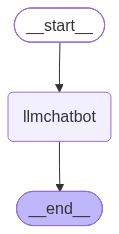

In [8]:
graph


In [9]:
response=graph.invoke({"messages": "Hi"})
response["messages"][-1].content

'Hello! How can I help you today?'

## Chatbot with tool

In [10]:
from langchain_tavily import TavilySearch
tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

schema of custom tool funciton

In [11]:
# @Tool
def fucntion(a:int , b:int)-> int:
    """ summary
    Args
        a : int __description__
        b : int __description__
    return
        r : int 
    """
    return a+b


creating custom fuction as tool 

In [12]:
# from langchain_core.tools import tool

def mutlipication(a:int , b:int)-> int:
    """ multiplication of  numbers
    Args
        a : int first number
        b : int second number
    return
        r : int result
    """
    return a+b

binding tool to llm

In [13]:
Tools=[tool,mutlipication]
llm_with_tools=llm.bind_tools(Tools)
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.12', 'langchain': '1.4.6'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001DCC00B02F0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001DCC00B1010>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, a

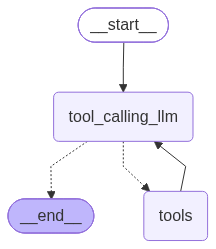

In [14]:
## stategraph
from langgraph.graph import START,END
from langgraph.prebuilt import ToolNode, tools_condition

## node defination
def tool_calling_llm(state:State):
    return {"messages": llm_with_tools.invoke(state["messages"])}

## graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools",ToolNode(Tools))
## add edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # if latest message (result) from assistant is a tool call -> tools_condition routes to Tools
    # if latest message (result) from assistant is not a tool call -> tools_condition routes to tool_calling_llm
      tools_condition
)
builder.add_edge("tools","tool_calling_llm")
# builder.add_edge("tool_calling_llm","Tools")

graph=builder.compile()
graph

In [43]:
response=graph.invoke({"messages":"multiply 2 and 5"})
response

{'messages': [HumanMessage(content='multiply 2 and 5', additional_kwargs={}, response_metadata={}, id='3ddd5e32-20b2-4c00-8e12-8c3e8abf3e12'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'User wants multiplication of 2 and 5. Use function.', 'tool_calls': [{'id': 'fc_9a1e1131-3f4a-457d-8824-54481682cc5d', 'function': {'arguments': '{"a":2,"b":5}', 'name': 'mutlipication'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 373, 'total_tokens': 423, 'completion_time': 0.204062743, 'completion_tokens_details': {'reasoning_tokens': 14}, 'prompt_time': 0.817210719, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.56279522, 'total_time': 1.021273462}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4140daa9c2', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a16413-c71a-75c5-943b-6f865fb0a31a-0', tool_calls=[{'name': 'mutl

In [44]:
display(Markdown(response["messages"][-1].content))

The product of 2 × 5 is **10**.

In [45]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

multiply 2 and 5
================================== Ai Message ==================================
Tool Calls:
  mutlipication (fc_9a1e1131-3f4a-457d-8824-54481682cc5d)
 Call ID: fc_9a1e1131-3f4a-457d-8824-54481682cc5d
  Args:
    a: 2
    b: 5
================================= Tool Message =================================
Name: mutlipication

7
================================== Ai Message ==================================

The product of 2 × 5 is **10**.


In [46]:
response2=graph.invoke({"messages":" addition 765765763 & 76998687894 and give recents new in pune?"})
display(Markdown(response2["messages"][-1].content))

**Sum**

\[
765{,}765{,}763 \;+\; 76{,}998{,}687{,}894 \;=\; 77{,}764{,}453{,}657
\]

**Recent news from Pune (as of 22 October 2026)**  

| Headline | What happened | Why it matters |
|----------|---------------|----------------|
| **Violent clash over water‑use in a housing society** | A dispute erupted when residents of a Pune housing society objected to a neighbour washing a vehicle with society‑supplied water. The confrontation turned violent, leaving **7 people injured**. Police were called and an FIR was lodged. | Highlights growing tensions over water scarcity and the need for stricter community‑resource management. [[source ①](https://timesofindia.indiatimes.com/city/pune/dispute-in-pune-housing-society-over-water-use-to-wash-vehicle-turns-violent-7-injured/amp_articleshow/135100117.cms)] |
| **Two arrested, minor detained for a ₹2 Lakh assault on a shipping‑firm owner** | Police arrested two suspects and detained a minor after a **₹2  lakh** physical assault was reported against the owner of a local shipping company. The case is being investigated under the Indian Penal Code for criminal assault and extortion. | Shows law‑enforcement’s swift response to commercial‑sector crimes and raises concerns about safety for business owners in the city. [[source ②](https://timesofindia.indiatimes.com/city/pune/two-arrested-minor-detained-for-rs-2l-hit-on-shipping-firm-owner/articleshow/135099800.cms)] |
| **Christian Philosophers release a three‑volume encyclopedia** | The Association of Christian Philosophers of India (ACPI) marked its Golden Jubilee in Pune by unveiling a revised, three‑volume *Encyclopedia of Christian Philosophy*. The event drew scholars from across the country. | Signals Pune’s growing role as a hub for academic and cultural events, especially in the humanities. [[source ③](https://catholicconnect.in/news/christian-philosophers-release-encyclopedia-at-national-seminar-in-pune)] |

**Takeaway**

- The **total of the two numbers you asked about is 77,764,453,657**.  
- Pune’s latest headlines show a mix of **community‑level conflicts (water‑use dispute)**, **criminal activity affecting business owners**, and **cultural‑academic milestones**. These stories reflect the city’s dynamic social, economic, and intellectual landscape as of late October 2026.

## Adding memory in Agentic Graph

using checkpointer=memorySaver()

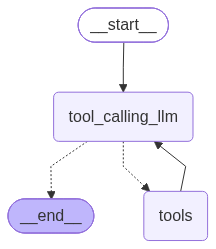

In [15]:
## stategraph
from langgraph.graph import START,END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver

## MemorySaver instance
memory=MemorySaver()


## node defination
def tool_calling_llm(state:State):
    return {"messages": llm_with_tools.invoke(state["messages"])}

## graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools",ToolNode(Tools))
## add edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # if latest message (result) from assistant is a tool call -> tools_condition routes to Tools
    # if latest message (result) from assistant is not a tool call -> tools_condition routes to tool_calling_llm
      tools_condition
)
builder.add_edge("tools","tool_calling_llm")
# builder.add_edge("tool_calling_llm","Tools")

graph=builder.compile(checkpointer=memory)
graph

In [16]:
config={"configurable":{"thread_id":"modi12"}}
response=graph.invoke({"messages": "my friend is pm modi"}, config=config)


In [54]:
config={"configurable":{"thread_id":"modi12"}}
response=graph.invoke({"messages": "who is my friend "}, config=config)
display(Markdown(response["messages"][-1].content))

Your friend is **Narendra Modi**, the Prime Minister of India.

In [57]:
response

{'messages': [HumanMessage(content='my friend is pm modi', additional_kwargs={}, response_metadata={}, id='f9063983-4349-407e-b3d8-7da21d2d2cd7'),
  AIMessage(content='That’s interesting! How can I assist you regarding Prime Minister Narendra\u202fModi? Whether you’d like background information, recent news, policy details, or anything else, just let me know.', additional_kwargs={'reasoning_content': 'The user says "my friend is pm modi". Likely they want some response. Could be a statement. They might be implying they are friends with PM Modi, maybe they want info about him? Could ask for details. The user hasn\'t asked a question. We need to respond politely, maybe ask how can I help. Should we provide info about PM Modi? Probably respond acknowledging and ask what they need.'}, response_metadata={'token_usage': {'completion_tokens': 131, 'prompt_tokens': 372, 'total_tokens': 503, 'completion_time': 0.276366245, 'completion_tokens_details': {'reasoning_tokens': 83}, 'prompt_time': 0.

What should you do in a real AI chatbot?
- Learning and development: MemorySaver() is fine.
- Production: Use a persistent checkpointer, such as PostgreSQL, and implement a retention policy if conversations should expire.
- **Privacy**: Avoid storing sensitive information unnecessarily, and explicitly delete data when required.
One more important detail: MemorySaver() is in-memory storage, so saved checkpoints are lost when its Python process terminates. This does not mean every other kind of application memory or database data is cleared.

creating superbot


In [17]:
def superbot(state:State):
    return {"messages": [llm.invoke(state["messages"])]}

In [22]:
graph=StateGraph(State)

graph.add_node("superbot",superbot)

graph.add_edge(START,"superbot")
graph.add_edge("superbot", END)
memory=MemorySaver()
builder=graph.compile(checkpointer=memory)
builder
config= {"configurable":{"thread_id":"pm2"}}

In [23]:
from IPython.display import display,Markdown
res=builder.invoke({"messages":"what is stream_mode=update and stream_mode=values"},config=config)
display(Markdown(res["messages"][-1].content))

Below is a concise, practical guide to the two streaming options that you can now pass to the **Chat Completion** endpoint (and a few related OpenAI endpoints) via the `stream_mode` query‑parameter:

| Mode | What you receive | When you get it | Typical use‑cases | Example payload |
|------|------------------|----------------|-------------------|-----------------|
| **`stream_mode=update`** | **Delta updates** – each chunk contains the *incremental* change (the new token or a tiny piece of a JSON field). | As soon as the model produces **any** new token, the server pushes a chunk. | • Real‑time UI that wants to show text as soon as it appears (typing‑assistant, live‑coding helpers). <br>• Low‑latency pipelines where you start processing the output before it’s finished (e.g., streaming summarisation, incremental sentiment analysis). | ```json\n{ "id":"chatcmpl‑…","choices":[{ "delta":{ "content":"H" },"index":0,"finish_reason":null }],"object":"chat.completion.chunk"}\n``` |
| **`stream_mode=values`** | **Complete values** – each chunk contains a *self‑contained* value (a full message, a complete function‑call argument, a finished JSON object). | Only when the model has finished constructing the **entire** value for that field. | • Applications that need a **well‑formed** JSON payload on every step (e.g., function‑calling, structured data extraction). <br>• UI that prefers to avoid “partial” fragments (e.g., a chat bubble that appears only when the assistant’s reply is ready). | ```json\n{ "id":"chatcmpl‑…","choices":[{ "delta":{ "content":"Hello, how can I help you today?" },"index":0,"finish_reason":"stop" }],"object":"chat.completion.chunk"}\n``` |

---

## 1. Why the two modes exist

- **Latency vs. safety** – `update` gives you the lowest possible latency (a new token every ~ 100 ms) but you have to stitch the pieces together yourself and be prepared for malformed JSON fragments.  
- **Structure & simplicity** – `values` trades a little latency for a guarantee that each chunk is a *complete* piece of data, which makes downstream parsing far easier.

Both modes still use the same underlying streaming transport (HTTP chunked transfer) and the same authentication, rate‑limit, and pricing rules. The only difference is **what the server decides to emit**.

---

## 2. Detailed behaviour

### `stream_mode=update`

| Aspect | Detail |
|--------|--------|
| **Chunk granularity** | Token‑level for plain text (`content`), field‑level for structured output (`function_call.arguments`). |
| **`finish_reason`** | Sent only on the *final* chunk (`stop`, `length`, `tool_calls`, etc.). Intermediate chunks have `null`. |
| **Re‑assembly** | You must concatenate `delta.content` (or `delta.function_call.arguments`) in order. |
| **Error handling** | If the model aborts mid‑JSON, you may receive an invalid fragment; you should fall back to a safe‑parse strategy (e.g., try‑catch on each chunk). |
| **Typical code pattern** (Node.js) | ```js\nlet full = '';\nfor await (const chunk of response) {\n  const delta = chunk.choices[0].delta?.content;\n  if (delta) full += delta;\n  if (chunk.choices[0].finish_reason) break;\n}\n``` |

### `stream_mode=values`

| Aspect | Detail |
|--------|--------|
| **Chunk granularity** | Whole‑message granularity. For a normal chat reply you’ll get **exactly one** chunk (the finished assistant message). For function calls you’ll get a single chunk that contains the *entire* `arguments` JSON string. |
| **`finish_reason`** | Present on the same chunk that carries the value, because the chunk marks the completion of that value. |
| **Re‑assembly** | No manual stitching required – you can parse the payload immediately. |
| **Error handling** | Since the server only sends a chunk when it has a valid JSON value, you can safely `JSON.parse` without guarding against partial data. |
| **Typical code pattern** (Python) | ```python\nfull_msg = None\nasync for chunk in response:\n    if 'content' in chunk['choices'][0]['delta']:\n        full_msg = chunk['choices'][0]['delta']['content']\n        break\nprint(full_msg)\n``` |

---

## 3. Choosing the right mode

| Decision factor | `update` | `values` |
|-----------------|----------|----------|
| **Need sub‑second UI feedback?** | ✅ | ❌ (you’ll wait for the whole message) |
| **Parsing structured output (function calls, JSON, CSV)?** | ⚠️ (you must buffer until you see a closing brace) | ✅ (guaranteed complete) |
| **Bandwidth constraints** | Slightly higher overhead (more HTTP headers per token) | Slightly lower overhead (fewer chunks) |
| **Complexity budget** | Higher (you need a buffer & concatenation logic) | Lower (just read the chunk) |

A common hybrid approach is:

```python
if want_real_time_typing:
    mode = "update"
else:
    mode = "values"
```

You can also **switch** on a per‑request basis: start with `update` for the first few tokens, and once you detect a function‑call pattern, re‑issue the request with `values` to get the full argument block in one go.

---

## 4. Example end‑to‑end

### a) Plain chat with `update`

```bash
curl https://api.openai.com/v1/chat/completions \
  -H "Authorization: Bearer $OPENAI_API_KEY" \
  -H "Content-Type: application/json" \
  -d '{
        "model":"gpt-4o-mini",
        "messages":[{"role":"user","content":"Tell me a joke"}],
        "stream":true,
        "stream_mode":"update"
      }' \
  --no-buffer
```

**What you see on the wire (trimmed):**

```
data: {"id":"chatcmpl-…","choices":[{"delta":{"content":"Why"},"index":0,"finish_reason":null}],"object":"chat.completion.chunk"}

data: {"id":"chatcmpl-…","choices":[{"delta":{"content":" did"},"index":0,"finish_reason":null}],"object":"chat.completion.chunk"}

...
data: {"id":"chatcmpl-…","choices":[{"delta":{"content":" the chicken cross the road?"},"index":0,"finish_reason":"stop"}],"object":"chat.completion.chunk"}
```

You concatenate the `content` fields to get the final joke.

### b) Function call with `values`

```bash
curl https://api.openai.com/v1/chat/completions \
  -H "Authorization: Bearer $OPENAI_API_KEY" \
  -H "Content-Type: application/json" \
  -d '{
        "model":"gpt-4o-mini",
        "messages":[{"role":"user","content":"Schedule a meeting tomorrow at 10 am"}],
        "functions":[{"name":"create_event","parameters":{...}}],
        "stream":true,
        "stream_mode":"values"
      }' \
  --no-buffer
```

**Chunk you receive (single, complete):**

```json
{
  "id":"chatcmpl-…",
  "choices":[{
    "delta":{
      "function_call":{
        "name":"create_event",
        "arguments":"{\"title\":\"Meeting\",\"date\":\"2026‑10‑24\",\"time\":\"10:00\"}"
      }
    },
    "index":0,
    "finish_reason":"tool_calls"
  }],
  "object":"chat.completion.chunk"
}
```

You can `JSON.parse` the `arguments` immediately and invoke your calendar API.

---

## 5. Edge‑cases & Gotchas

| Situation | `update` | `values` |
|-----------|----------|----------|
| **Model stops early (e.g., token limit)** | You’ll still receive a final chunk with `finish_reason":"length"`; the buffer may be incomplete, so guard against missing closing brackets. | Same final chunk, but because the chunk is *complete* (the model decided to stop), the JSON is still syntactically valid. |
| **Tool‑call streaming** (multiple calls) | You’ll see a series of tiny `function_call` deltas; you must merge them until you encounter a `finish_reason` of `"tool_calls"`. | You receive **one** chunk per tool call, each containing the whole argument block. |
| **Non‑ASCII characters** | Tokens may split a multibyte UTF‑8 code point; most clients handle this fine because the API sends UTF‑8 bytes, but you must treat the buffer as a **byte** array, not a string, when concatenating. | No split – the whole string arrives already encoded correctly. |
| **Rate‑limit bursts** | Because you send more HTTP packets, you might hit a higher “requests per second” metric on some proxies. | Fewer packets → lower risk of burst‑limit errors. |

---

## 6. Quick cheat‑sheet for developers

| Language | `update` snippet | `values` snippet |
|----------|------------------|------------------|
| **Node (fetch)** | ```js\nconst resp = await fetch(url, {method:'POST',body:JSON.stringify(payload)});\nfor await (const chunk of resp.body) { /* parse each delta */ }\n``` | ```js\nconst resp = await fetch(url, {method:'POST',body:JSON.stringify({...payload, stream_mode:'values'})});\nconst data = await resp.json(); // one‑shot\n``` |
| **Python (httpx)** | ```python\nasync with httpx.AsyncClient() as client:\n    async for line in client.stream('POST', url, json=payload):\n        obj = json.loads(line[6:])   # strip \"data: \"\n        # handle obj['choices'][0]['delta']\n``` | ```python\nresp = httpx.post(url, json={**payload, 'stream_mode':'values'}, stream=True)\nfor line in resp.iter_lines():\n    if line:\n       

## Streaming


Streaming = incremental token output from an LLM, enabling low‑latency, interactive, and cost‑effective applications.
.stream() – synchronous generator → for ev in app.stream(...): …
.astream() – asynchronous generator → async for ev in app.astream(...): …

In [ ]:
graph=StateGraph(State)

graph.add_node("superbot",superbot)

graph.add_edge(START,"superbot")
graph.add_edge("superbot", END)
memory=MemorySaver()
builder=graph.compile(checkpointer=memory)
builder


In [38]:
from IPython.display import display,Markdown
config= {"configurable":{"thread_id":"pm21"}}
for chunk in builder.stream({"messages":"your from?"},config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='99f1f9a8-6fe4-4b71-93bc-412d98c10fd2'), AIMessage(content="Hello! I'm doing great, thank you for asking. How can I assist you today?", additional_kwargs={'reasoning_content': 'We need to respond. The system says we are ChatGPT. The user says hello. We can respond politely. No special constraints.'}, response_metadata={'token_usage': {'completion_tokens': 55, 'prompt_tokens': 77, 'total_tokens': 132, 'completion_time': 0.114377607, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.003202301, 'prompt_tokens_details': None, 'queue_time': 0.399042516, 'total_time': 0.117579908}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c868cf1eaa', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1667e-e747-75c4-8484-580434bc0edf-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_t